# Planar dielectric optics

Reflection, refraction, resonant layers, evanescent coupling and slab confinement form a single sequence. Each experiment declares its own materials and illumination. Polarization retardance under total internal reflection closes the sequence.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from numpy.testing import assert_allclose

%matplotlib inline

plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)

um = 1e-6
wavelength = 0.532 * um

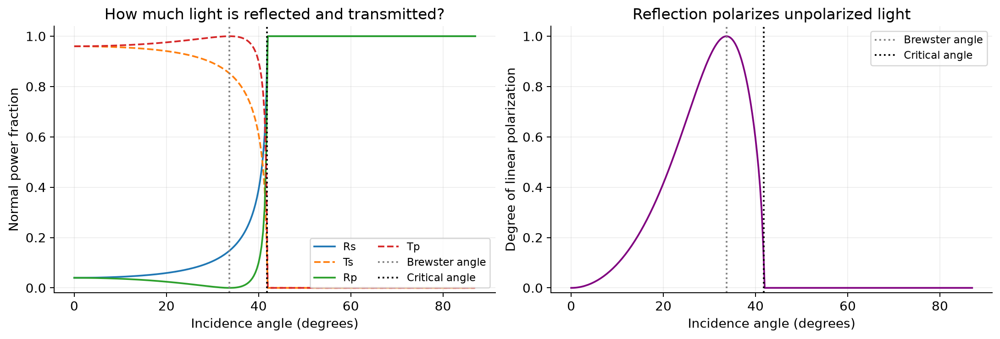

Brewster angle: 33.69°; critical angle: 41.81°


In [2]:
glass = optics.HomogeneousRegion("glass", optics.Dielectric(1.5))
air = optics.HomogeneousRegion("air", optics.Dielectric(1.0))
interface = optics.PlanarInterface(optics.Frame(), glass, air)

n1, n2 = glass.material.n, air.material.n
brewster = np.arctan(n2 / n1)
critical = np.arcsin(n2 / n1)


def plane_wave(angle, polarization="s"):
    direction = np.array([np.sin(angle), 0, np.cos(angle)])
    electric = (
        np.array([0, 1, 0])
        if polarization == "s"
        else np.array([np.cos(angle), 0, -np.sin(angle)])
    )

    return optics.PlaneWaveExpansion(
        [2 * np.pi * n1 / wavelength * direction],
        [electric],
        [0, 0, 0],
        wavelength,
        glass,
    )


probe = optics.PointGrid([[0, 0, 0]])
angles = np.unique(np.r_[np.linspace(0, 87, 260) * np.pi / 180, brewster])
reflectance, transmittance = {}, {}

for polarization in ("s", "p"):
    reflected_power, transmitted_power = [], []

    for angle in angles:
        source = plane_wave(angle, polarization)
        solution = optics.scatter_plane(source, interface)
        incident_flux = source.evaluate(probe).poynting()[0, 2]
        reflected_flux = solution.reflected.evaluate(probe).poynting()[0, 2]
        transmitted_flux = solution.transmitted.evaluate(probe).poynting()[0, 2]

        reflected_power.append(-reflected_flux / incident_flux)
        transmitted_power.append(transmitted_flux / incident_flux)

    reflectance[polarization] = np.array(reflected_power)
    transmittance[polarization] = np.array(transmitted_power)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for polarization in ("s", "p"):
    axes[0].plot(
        np.degrees(angles), reflectance[polarization], label=f"R{polarization}"
    )
    axes[0].plot(
        np.degrees(angles), transmittance[polarization], "--", label=f"T{polarization}"
    )

# An unpolarized source is an incoherent equal mixture of s and p, not a Jones vector.
Rs, Rp = reflectance["s"], reflectance["p"]
linear_polarization = np.abs(Rs - Rp) / (Rs + Rp)
axes[1].plot(np.degrees(angles), linear_polarization, color="purple")

for ax in axes:
    ax.axvline(np.degrees(brewster), color="gray", ls=":", label="Brewster angle")
    ax.axvline(np.degrees(critical), color="black", ls=":", label="Critical angle")
    ax.set(xlabel="Incidence angle (degrees)", ylim=(-0.02, 1.04))
    ax.grid(alpha=0.2)

axes[0].set(
    ylabel="Normal power fraction", title="How much light is reflected and transmitted?"
)
axes[1].set(
    ylabel="Degree of linear polarization",
    title="Reflection polarizes unpolarized light",
)
axes[0].legend(ncol=2, fontsize=9)
axes[1].legend(fontsize=9)
plt.show()

for polarization in ("s", "p"):
    assert_allclose(
        reflectance[polarization] + transmittance[polarization], 1, atol=2e-13
    )

print(
    f"Brewster angle: {np.degrees(brewster):.2f}°; critical angle: {np.degrees(critical):.2f}°"
)

The p-reflection minimum explains polarized glare: near Brewster incidence the
reflected field contains almost only s polarization. Above the critical angle,
$R_s=R_p=1$; the reflected unpolarized mixture is no longer preferentially s or p.

## Watch a finite beam meet the interface

We construct a narrow Gaussian angular distribution, rather than assigning one
ray direction to an entire finite beam. Each mode is refracted independently.
The panels share the same electric-field scale. White arrows indicate local
Poynting-flow **direction**, not magnitude. The white line is the material boundary.

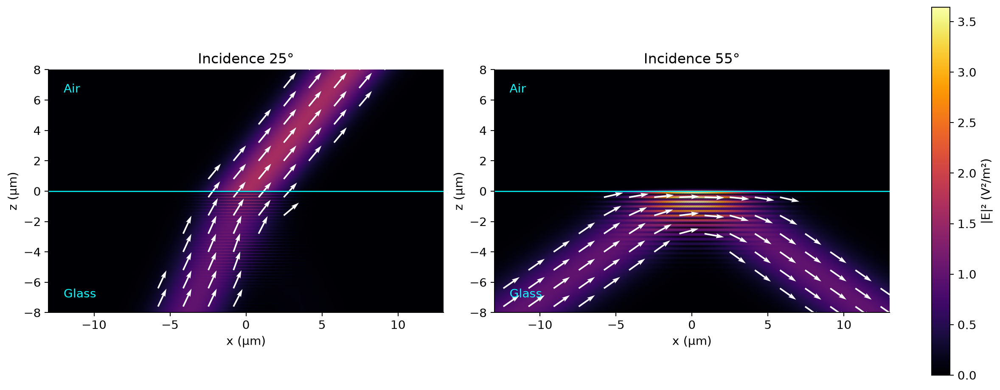

In [3]:
def gaussian_beam(angle, waist=3 * um, count=61):
    spread = 2 / (2 * np.pi * n1 / wavelength * waist)
    theta = angle + np.linspace(-4 * spread, 4 * spread, count)
    amplitudes = np.exp(-(((theta - angle) / spread) ** 2))
    amplitudes /= amplitudes.sum()
    directions = np.column_stack((np.sin(theta), np.zeros(count), np.cos(theta)))
    electric = np.zeros((count, 3), dtype=complex)
    electric[:, 1] = amplitudes

    return optics.PlaneWaveExpansion(
        2 * np.pi * n1 / wavelength * directions, electric, [0, 0, 0], wavelength, glass
    )


x = np.linspace(-13, 13, 221) * um
z = np.linspace(-8, 8, 161) * um
X, Z = np.meshgrid(x, z)
points = np.stack((X, np.zeros_like(X), Z), axis=-1)
below = Z <= 0
beam_maps = []

for degrees in (25, 55):
    source = gaussian_beam(np.deg2rad(degrees))
    solution = optics.scatter_plane(source, interface)
    electric = np.zeros(points.shape, dtype=complex)
    flow = np.zeros(points.shape)

    for mask, side in ((below, "minus"), (~below, "plus")):
        field = solution.evaluate(optics.PointGrid(points[mask]), side=side)
        electric[mask] = field.electric.values
        flow[mask] = field.poynting()

    beam_maps.append((electric, flow))

peak = max(np.max(np.sum(abs(electric) ** 2, axis=-1)) for electric, _ in beam_maps)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

for ax, degrees, (electric, flow) in zip(axes, (25, 55), beam_maps):
    norm = np.sum(abs(electric) ** 2, axis=-1)
    image = ax.pcolormesh(
        x / um, z / um, norm, cmap="inferno", vmin=0, vmax=peak, shading="gouraud"
    )
    ax.axhline(0, color="cyan", lw=1)
    ax.text(-12, -7, "Glass", color="cyan")
    ax.text(-12, 6.5, "Air", color="cyan")

    step = (slice(4, None, 12), slice(5, None, 14))
    direction = flow / np.maximum(np.linalg.norm(flow, axis=-1, keepdims=True), 1e-30)
    visible = norm[step] > 0.06 * peak
    ax.quiver(
        X[step][visible] / um,
        Z[step][visible] / um,
        direction[step][visible, 0],
        direction[step][visible, 2],
        color="white",
        scale=20,
        width=0.004,
    )
    ax.set(
        xlabel="x (µm)", ylabel="z (µm)", title=f"Incidence {degrees}°", aspect="equal"
    )

fig.colorbar(image, ax=axes, label="|E|² (V²/m²)")
plt.show()

At 25° the transmitted beam bends away from the normal as it enters lower-index
air. At 55° the incident and reflected beams interfere in glass, while only a
thin evanescent layer appears in air. A narrower waist broadens the angular
spectrum: near the critical angle, some components can transmit while others
undergo total internal reflection.

## The evanescent field is nonzero, and its electric vector rotates

For a single p-polarized wave above critical incidence, $k_z=i\kappa$.
The amplitude penetration length is $1/\kappa$, while $|E|^2$ decays twice as
fast. The longitudinal and tangential electric components are in quadrature.

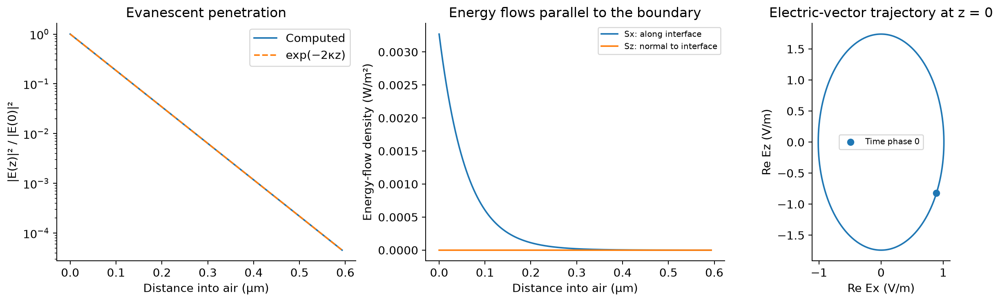

Amplitude penetration length: 0.119 µm


In [4]:
angle = np.deg2rad(55)
tir = optics.scatter_plane(plane_wave(angle, "p"), interface)
kappa = tir.transmitted.wavevectors[0, 2].imag
penetration = 1 / kappa
heights = np.linspace(0, 5 * penetration, 150)
line = optics.PointGrid(
    np.column_stack((np.zeros_like(heights), np.zeros_like(heights), heights))
)
field = tir.transmitted.evaluate(line)

phase = np.linspace(0, 2 * np.pi, 300)
E0 = field.electric.values[0]
ellipse = np.real(E0[:, None] * np.exp(-1j * phase))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
axes[0].semilogy(
    heights / um, field.electric.norm2() / field.electric.norm2()[0], label="Computed"
)
axes[0].semilogy(heights / um, np.exp(-2 * kappa * heights), "--", label="exp(−2κz)")
axes[0].set(
    xlabel="Distance into air (µm)",
    ylabel="|E(z)|² / |E(0)|²",
    title="Evanescent penetration",
)
axes[0].legend()

flow = field.poynting()
axes[1].plot(heights / um, flow[:, 0], label="Sx: along interface")
axes[1].plot(heights / um, flow[:, 2], label="Sz: normal to interface")
axes[1].set(
    xlabel="Distance into air (µm)",
    ylabel="Energy-flow density (W/m²)",
    title="Energy flows parallel to the boundary",
)
axes[1].legend(fontsize=8)

axes[2].plot(ellipse[0], ellipse[2])
axes[2].scatter(ellipse[0, 0], ellipse[2, 0], label="Time phase 0")
axes[2].set(
    xlabel="Re Ex (V/m)",
    ylabel="Re Ez (V/m)",
    title="Electric-vector trajectory at z = 0",
    aspect="equal",
)
axes[2].legend(fontsize=8)
plt.show()

assert_allclose(flow[:, 2], 0, atol=1e-15)
print(f"Amplitude penetration length: {penetration / um:.3f} µm")

**Try next:** change the beam angle to 40°, reduce its waist, or replace glass–air
with air–glass. Compare s and p finite beams. The API sequence stays the same:
construct a modal source, call `scatter_plane`, then evaluate each physical side.
Exactly critical or grazing incidence is excluded by the present solver; approach
those angles from either side rather than evaluating the singular representation.

# Coherent planar layers: resonances and optical tunneling

A dielectric slab is a simple interferometer. Its reflected waves can cancel,
leaving unit transmission even though each individual interface reflects light.
A thin air gap between two glass regions does something different: above the
critical angle, two evanescent tails couple and transmit energy across the gap.

We will see Fabry–Pérot fringes, internal standing waves, and the disappearance
of frustrated total internal reflection as the gap widens. The library sums all
coherent round trips for infinite parallel planes; this is not a finite cavity
or a lateral waveguide. Change slab thickness, index contrast and incidence angle.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from numpy.testing import assert_allclose

%matplotlib inline

plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)

um = 1e-6
wavelength = 0.532 * um

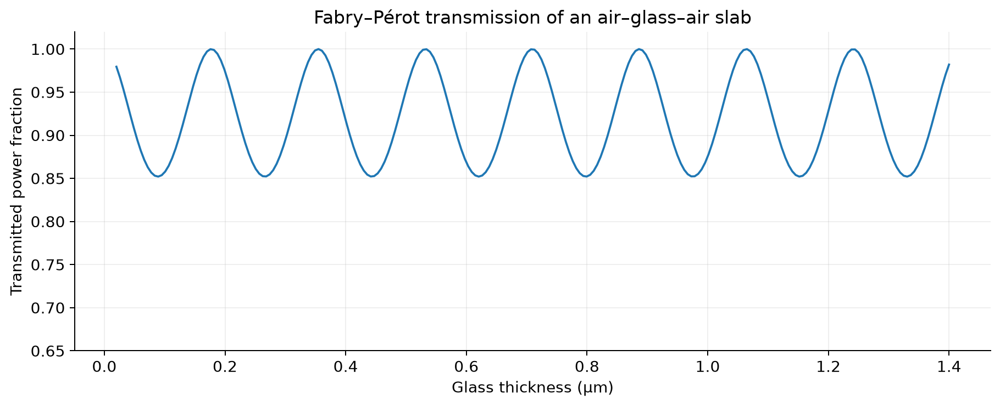

In [6]:
air_in = optics.HomogeneousRegion("entrance air", optics.Dielectric(1))
glass = optics.HomogeneousRegion("film", optics.Dielectric(1.5))
air_out = optics.HomogeneousRegion("exit air", optics.Dielectric(1))
probe = optics.PointGrid([[0, 0, 0]])


def wave(region, angle=0):
    direction = np.array([np.sin(angle), 0, np.cos(angle)])

    return optics.PlaneWaveExpansion(
        [2 * np.pi * region.material.n / wavelength * direction],
        [[0, 1, 0]],
        [0, 0, 0],
        wavelength,
        region,
    )


source = wave(air_in)
input_flux = source.evaluate(probe).poynting()[0, 2]
thicknesses = np.linspace(0.02, 1.4, 240) * um
transmission = []

for thickness in thicknesses:
    stack = optics.LayerStack((air_in, glass, air_out), (thickness,))
    solution = optics.propagate_layers(source, stack)
    output = solution.evaluate(optics.PointGrid([[0, 0, thickness]]), region=2)
    transmission.append(output.poynting()[0, 2] / input_flux)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.plot(thicknesses / um, transmission)
ax.set(
    xlabel="Glass thickness (µm)",
    ylabel="Transmitted power fraction",
    title="Fabry–Pérot transmission of an air–glass–air slab",
    ylim=(0.65, 1.02),
)
ax.grid(alpha=0.2)
plt.show()

Resonances occur when $2 n d$ is an integer multiple of the vacuum wavelength.
An internally enhanced standing wave does not imply enhanced net transmitted
power: forward and backward fluxes must be combined.

## Look inside a resonant and an off-resonant film

We evaluate each point in its actual material region. The real-field panels
show a time snapshot; the power curves use both complex E and H.

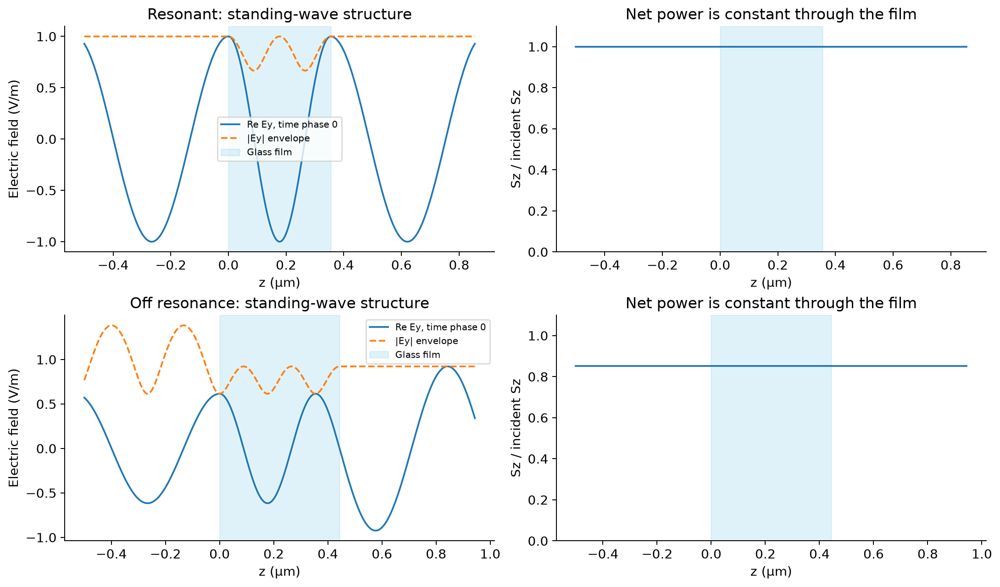

In [7]:
resonant = 2 * wavelength / (2 * glass.material.n)
off_resonant = 2.5 * wavelength / (2 * glass.material.n)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")

for row, (label, thickness) in enumerate(
    (("Resonant", resonant), ("Off resonance", off_resonant))
):
    stack = optics.LayerStack((air_in, glass, air_out), (thickness,))
    solution = optics.propagate_layers(source, stack)
    z = np.linspace(-0.5 * um, thickness + 0.5 * um, 650)
    electric = np.zeros((len(z), 3), dtype=complex)
    flow = np.zeros(len(z))

    masks = (z < 0, (z >= 0) & (z <= thickness), z > thickness)

    for region, mask in enumerate(masks):
        points = np.column_stack((np.zeros(mask.sum()), np.zeros(mask.sum()), z[mask]))
        field = solution.evaluate(optics.PointGrid(points), region=region)
        electric[mask] = field.electric.values
        flow[mask] = field.poynting()[:, 2]

    axes[row, 0].plot(z / um, electric[:, 1].real, label="Re Ey, time phase 0")
    axes[row, 0].plot(z / um, abs(electric[:, 1]), "--", label="|Ey| envelope")
    axes[row, 1].plot(z / um, flow / input_flux)

    for ax in axes[row]:
        ax.axvspan(0, thickness / um, color="skyblue", alpha=0.25, label="Glass film")
        ax.set(xlabel="z (µm)")

    axes[row, 0].set(
        ylabel="Electric field (V/m)", title=f"{label}: standing-wave structure"
    )
    axes[row, 1].set(
        ylabel="Sz / incident Sz",
        title="Net power is constant through the film",
        ylim=(0, 1.1),
    )
    axes[row, 0].legend(fontsize=8)
    assert_allclose(flow, flow[0], atol=1e-14)

plt.show()

## Frustrated total internal reflection: glass–air–glass

At 55° a single glass–air boundary would totally reflect. Put a second glass
region less than a wavelength away and the combined boundary problem supports
nonzero transmitted power. Inside the gap both evanescent branches are present;
their interference carries normal energy flow.

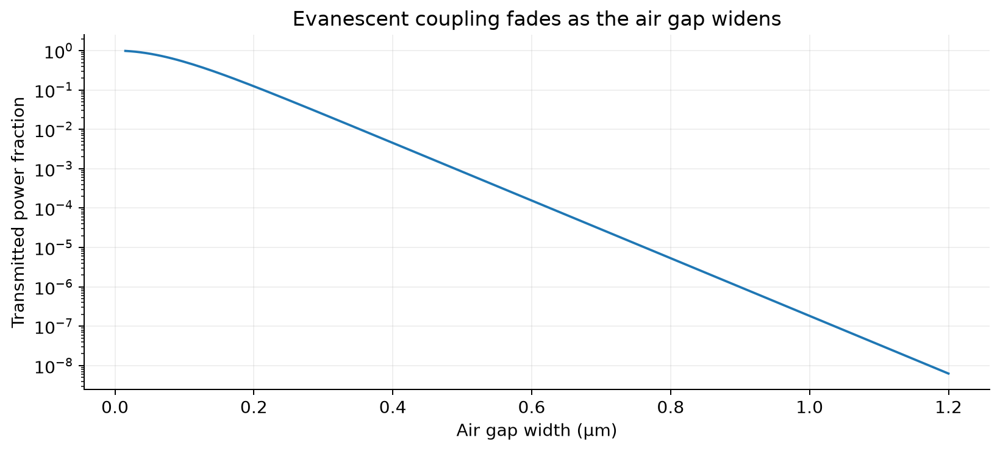

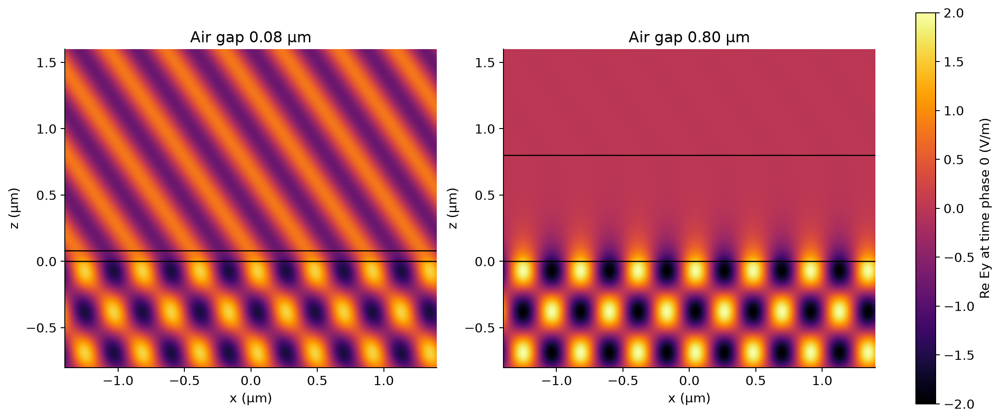

In [8]:
left = optics.HomogeneousRegion("left glass", optics.Dielectric(1.5))
gap = optics.HomogeneousRegion("air gap", optics.Dielectric(1))
right = optics.HomogeneousRegion("right glass", optics.Dielectric(1.5))
source = wave(left, np.deg2rad(55))
input_flux = source.evaluate(probe).poynting()[0, 2]
gaps = np.linspace(0.015, 1.2, 160) * um
transmission = []

for width in gaps:
    solution = optics.propagate_layers(
        source, optics.LayerStack((left, gap, right), (width,))
    )
    field = solution.evaluate(optics.PointGrid([[0, 0, width]]), region=2)
    transmission.append(field.poynting()[0, 2] / input_flux)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.semilogy(gaps / um, transmission)
ax.set(
    xlabel="Air gap width (µm)",
    ylabel="Transmitted power fraction",
    title="Evanescent coupling fades as the air gap widens",
)
ax.grid(alpha=0.2)
plt.show()

x = np.linspace(-1.4, 1.4, 141) * um
z = np.linspace(-0.8, 1.6, 181) * um
X, Z = np.meshgrid(x, z)
points = np.stack((X, np.zeros_like(X), Z), axis=-1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")

for ax, width in zip(axes, (0.08 * um, 0.8 * um)):
    solution = optics.propagate_layers(
        source, optics.LayerStack((left, gap, right), (width,))
    )
    electric = np.zeros(points.shape, dtype=complex)

    for region, mask in enumerate((Z < 0, (Z >= 0) & (Z <= width), Z > width)):
        field = solution.evaluate(optics.PointGrid(points[mask]), region=region)
        electric[mask] = field.electric.values

    image = ax.pcolormesh(
        x / um,
        z / um,
        electric[..., 1].real,
        cmap="inferno",
        vmin=-2,
        vmax=2,
        shading="gouraud",
    )
    ax.axhline(0, color="black", lw=1)
    ax.axhline(width / um, color="black", lw=1)
    ax.set(
        xlabel="x (µm)",
        ylabel="z (µm)",
        title=f"Air gap {width / um:.2f} µm",
        aspect="equal",
    )

fig.colorbar(image, ax=axes, label="Re Ey at time phase 0 (V/m)")
plt.show()

The thin gap allows a visible outgoing traveling wave. The wide gap leaves an
incident/reflected standing pattern on the left and only a weak outgoing wave
on the right. Try p polarization or sweep the incidence angle. These are coherent
infinite-plane calculations: finite beam footprints and lateral edges would
require additional spatial modeling.

# A planar dielectric waveguide: a confined field that propagates

A high-index slab can guide light along z while the field decays into the
surrounding lower-index material. We construct its fundamental even TE mode,
visualize the traveling field, and see how narrowing the core weakens confinement.

The library does not yet provide a waveguide eigensolver. We solve the scalar
TE dispersion equation explicitly below, then construct its exact piecewise
Maxwell fields using `PlaneWaveExpansion`. The example is uniform along y;
power integrated across x is therefore **power per unit width**, in W/m.

For half-width a, write $u=ha$, $w=\alpha a$, and
$V=k_0 a\sqrt{n_1^2-n_2^2}$. The even fundamental root obeys
$u\tan u=\sqrt{V^2-u^2}$ on $0<u<\min(V,\pi/2)$.

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from numpy.testing import assert_allclose

%matplotlib inline

plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)

um = 1e-6
wavelength = 0.532 * um

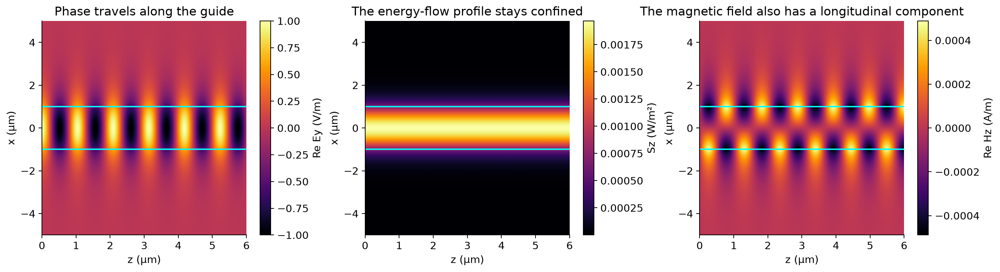

Effective refractive index: 1.482339


In [10]:
from scipy.integrate import trapezoid
from scipy.optimize import brentq

wavelength = 1.55 * um
core = optics.HomogeneousRegion("core", optics.Dielectric(1.5))
cladding = optics.HomogeneousRegion("cladding", optics.Dielectric(1.45))
k0 = 2 * np.pi / wavelength


def fundamental_mode(half_width):
    V = k0 * half_width * np.sqrt(core.material.n**2 - cladding.material.n**2)
    upper = min(V, np.pi / 2) * (1 - 1e-10)
    u = brentq(
        lambda value: value * np.tan(value) - np.sqrt(V**2 - value**2), 1e-12, upper
    )
    h = u / half_width
    beta = np.sqrt((k0 * core.material.n) ** 2 - h**2)
    alpha = np.sqrt(beta**2 - (k0 * cladding.material.n) ** 2)
    edge_amplitude = np.cos(u)

    inside = optics.PlaneWaveExpansion(
        [[h, 0, beta], [-h, 0, beta]],
        [[0, 0.5, 0], [0, 0.5, 0]],
        [0, 0, 0],
        wavelength,
        core,
    )
    left = optics.PlaneWaveExpansion(
        [[-1j * alpha, 0, beta]],
        [[0, edge_amplitude, 0]],
        [-half_width, 0, 0],
        wavelength,
        cladding,
    )
    right = optics.PlaneWaveExpansion(
        [[1j * alpha, 0, beta]],
        [[0, edge_amplitude, 0]],
        [half_width, 0, 0],
        wavelength,
        cladding,
    )

    return beta, (left, inside, right)


def evaluate_mode(points, half_width, expansions):
    electric = np.zeros(points.shape, dtype=complex)
    magnetic = np.zeros(points.shape, dtype=complex)
    x = points[..., 0]
    masks = (x < -half_width, abs(x) <= half_width, x > half_width)

    for expansion, mask in zip(expansions, masks):
        if not np.any(mask):
            continue

        field = expansion.evaluate(optics.PointGrid(points[mask]))
        electric[mask] = field.electric.values
        magnetic[mask] = field.magnetic

    return optics.ElectromagneticField(
        optics.ElectricField(optics.PointGrid(points), wavelength, electric), magnetic
    )


half_width = 1 * um
beta, expansions = fundamental_mode(half_width)
x = np.linspace(-5, 5, 241) * um
z = np.linspace(0, 6, 201) * um
X, Z = np.meshgrid(x, z)
points = np.stack((X, np.zeros_like(X), Z), axis=-1)
field = evaluate_mode(points, half_width, expansions)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
image = axes[0].pcolormesh(
    z / um,
    x / um,
    field.electric.Ey.real.T,
    cmap="inferno",
    vmin=-1,
    vmax=1,
    shading="gouraud",
)
fig.colorbar(image, ax=axes[0], label="Re Ey (V/m)")
image = axes[1].pcolormesh(
    z / um, x / um, field.poynting()[..., 2].T, cmap="inferno", shading="gouraud"
)
fig.colorbar(image, ax=axes[1], label="Sz (W/m²)")

image = axes[2].pcolormesh(
    z / um,
    x / um,
    field.magnetic[..., 2].real.T,
    cmap="inferno",
    shading="gouraud",
)
fig.colorbar(image, ax=axes[2], label="Re Hz (A/m)")
axes[2].set_title("The magnetic field also has a longitudinal component")

for ax in axes:
    ax.axhline(half_width / um, color="cyan")
    ax.axhline(-half_width / um, color="cyan")
    ax.set(xlabel="z (µm)", ylabel="x (µm)")

axes[0].set_title("Phase travels along the guide")
axes[1].set_title("The energy-flow profile stays confined")
plt.show()
print(f"Effective refractive index: {beta / k0:.6f}")

The two core waves interfere into $E_y=\cos(hx)e^{i\beta z}$. Outside, a complex
transverse wavevector creates evanescent decay. No reflected power is lost at
each conceptual bounce: this is one bound eigenmode of the whole structure.

## Make the core narrower

Each curve below uses the same central electric amplitude. The fraction of
power in the core, unlike the peak-normalized field alone, measures confinement.
The finite integration window is wide enough for the tails shown here.

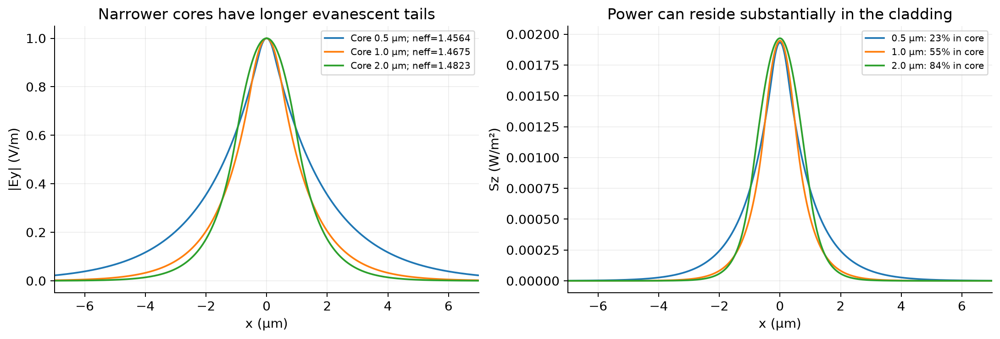

In [11]:
x_line = np.linspace(-25, 25, 4001) * um
points = np.column_stack((x_line, np.zeros_like(x_line), np.zeros_like(x_line)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for width in (0.5, 1.0, 2.0):
    a = width * um / 2
    beta, expansions = fundamental_mode(a)
    field = evaluate_mode(points, a, expansions)
    flux = field.poynting()[:, 2]
    inside = abs(x_line) <= a
    core_power = trapezoid(flux[inside], x_line[inside])
    total_power = trapezoid(flux, x_line)
    label = f"Core {width:.1f} µm; neff={beta / k0:.4f}"

    axes[0].plot(x_line / um, abs(field.electric.Ey), label=label)
    axes[1].plot(
        x_line / um,
        flux,
        label=f"{width:.1f} µm: {core_power / total_power:.0%} in core",
    )

    # E_y and tangential H_z must agree at each material face.
    for edge, left_index, right_index in ((-a, 0, 1), (a, 1, 2)):
        boundary = optics.PointGrid([[edge, 0, 0]])
        before = expansions[left_index].evaluate(boundary)
        after = expansions[right_index].evaluate(boundary)
        assert_allclose(before.electric.values, after.electric.values, atol=2e-12)
        assert_allclose(before.magnetic[:, 2], after.magnetic[:, 2], atol=2e-14)

for ax in axes:
    ax.set(xlabel="x (µm)", xlim=(-7, 7))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

axes[0].set(ylabel="|Ey| (V/m)", title="Narrower cores have longer evanescent tails")
axes[1].set(ylabel="Sz (W/m²)", title="Power can reside substantially in the cladding")
plt.show()

**Try next:** vary the index contrast or wavelength. The fundamental TE mode
remains guided in the ideal symmetric slab, but its extent can become much
larger than the core. Increase the integration window if its tails reach the
plot boundary. Higher-order and TM modes require their own dispersion branches;
they are not produced by changing an arbitrary label on this solution.

## Total internal reflection acts as a retarder

A linearly polarized plane wave contains equal s and p amplitudes and strikes a glass–air interface at 55°, above the critical angle. Reflection preserves the total power but gives s and p different phases, creating elliptical polarization.

To compare the actual polarization transverse to each ray, each observation grid uses its own right-handed `(s, p, propagation)` frame. These are cross sections of the separate incident and reflected waves, not the interference pattern of their sum.

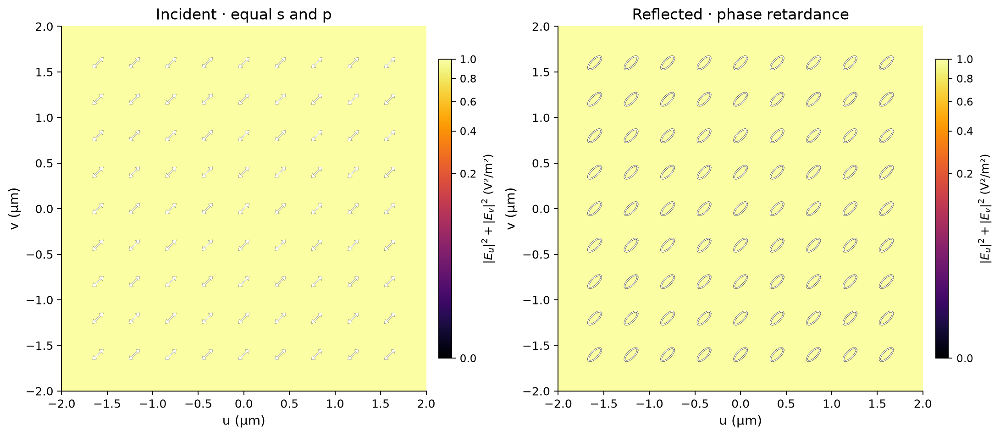

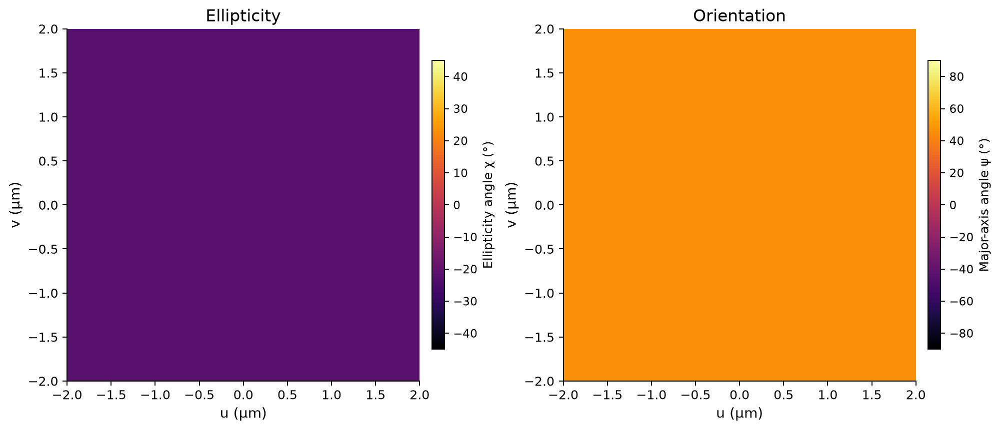

In [12]:
from vecdiff_general.visualization import (
    animate_polarization,
    plot_polarization,
    plot_polarization_scalar,
)

um = 1e-6
wavelength = 532e-9
air = optics.HomogeneousRegion("air", optics.Dielectric(1.0))

glass = optics.HomogeneousRegion("glass", optics.Dielectric(1.5))
interface = optics.PlanarInterface(optics.Frame(), glass, air)
angle = np.deg2rad(55)

direction = np.array([np.sin(angle), 0, np.cos(angle)])
s = np.array([0.0, 1.0, 0.0])
p = np.cross(direction, s)
incident_vector = (s + p) / np.sqrt(2)

source = optics.PlaneWaveExpansion(
    (2 * np.pi * 1.5 / wavelength * direction)[None, :],
    incident_vector[None, :],
    [0, 0, 0],
    wavelength,
    glass,
)
scattering = optics.scatter_plane(source, interface)
reflected_direction = np.array([np.sin(angle), 0, -np.cos(angle)])
reflected_p = np.cross(reflected_direction, s)

section_axis = np.linspace(-2, 2, 101) * um
incident_grid = optics.CartesianGrid(
    section_axis,
    section_axis,
    optics.Frame(basis=np.column_stack((s, p, direction))),
)
reflected_grid = optics.CartesianGrid(
    section_axis,
    section_axis,
    optics.Frame(basis=np.column_stack((s, reflected_p, reflected_direction))),
)
incident_field = source.evaluate(incident_grid)
reflected_field = scattering.reflected.evaluate(reflected_grid)

figure, axes = plt.subplots(1, 2, figsize=(12, 5.7), layout="constrained")

for axis, current_field, title in zip(
    axes,
    (incident_field, reflected_field),
    ("Incident · equal s and p", "Reflected · phase retardance"),
):
    plot_polarization(current_field, axis=axis, title=title, density=1.25)
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
plot_polarization_scalar(reflected_field, "ellipticity", axis=axes[0])
plot_polarization_scalar(reflected_field, "orientation", axis=axes[1])
plt.show()

## Read the rotation directly

Each electric arrow starts at the fixed center of its polarization ellipse and
ends at $\mathrm{Re}(\mathbf E e^{-i\omega t})$, with its head aligned with the
shaft. The relative phase between components and the spatial phase are retained.
There are no point markers. A linear arrow reaches full length at a turning point
and disappears at a zero crossing. Glyph lengths are normalized for display;
the background gives the projected field magnitude.

In [13]:
from IPython.display import HTML, display

animation = animate_polarization(
    reflected_field,
    frames=32,
    density=1.25,
    figsize=(5.6, 5.4),
    title="Reflected polarization · one optical cycle",
)
display(HTML(animation.to_jshtml()))
plt.close()